# Bloque 1 · Precio de compra de vivienda desde 2000

Una medida principal: **tasación de vivienda libre en €/m²**. España, comunidades y provincias: **2000–2025**. IPC: **2002–2025**. Municipios seleccionados: **2005–2025**.

La tasación no equivale al precio anunciado ni al precio efectivo de una transacción.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "data/snapshots/block01").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from spain_housing.prices_analysis import load_purchase_data, run_analysis, series_for

values, municipal, cpi, governments = load_purchase_data(ROOT)
purchase = series_for(values, level="national")
FIGURES = ROOT / "reports/figures/block01"
TABLES = ROOT / "reports/tables/block01"
def show(*names):
    for name in names:
        display(Image(filename=str(FIGURES / f"{name}.png")))


## 1. Evolución nacional

El código muestra directamente la serie utilizada.

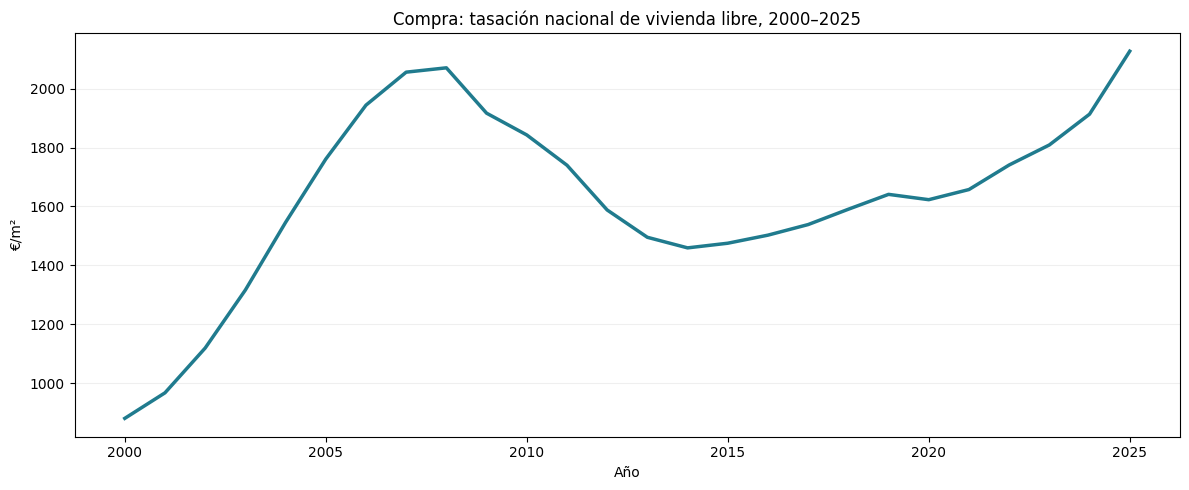

In [2]:
# Observaciones originales de tasación: una sola medida, sin encadenar otras fuentes.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(purchase.index, purchase, color="#207b8e", linewidth=2.5)
ax.set(title="Compra: tasación nacional de vivienda libre, 2000–2025", ylabel="€/m²", xlabel="Año")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)


## 2. Compra frente a los precios generales

Comparamos cuánto ha subido la compra respecto a los precios generales, medidos por el IPC. El IPC no indica si los ingresos han crecido al mismo ritmo.

,Cambio acumulado (%)
Compra: tasación €/m²,90.11
Precios generales (IPC),66.57


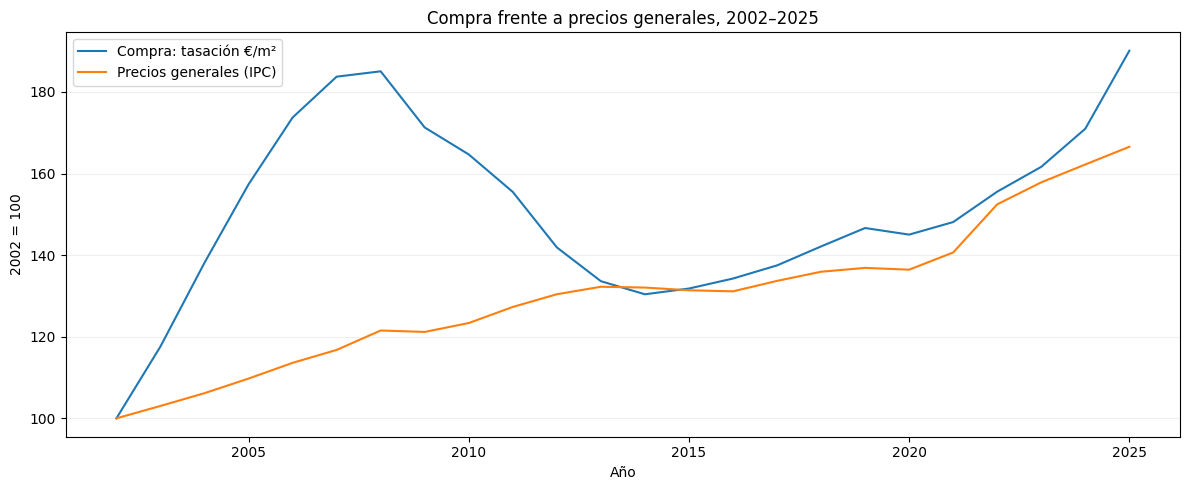

In [3]:
# La comparación empieza donde hay datos de ambas series: 2002.
years = sorted(set(purchase.index) & set(cpi.index))
base = years[0]
comparison = pd.DataFrame({
    "Compra: tasación €/m²": purchase.loc[years] / purchase.loc[base] * 100,
    "Precios generales (IPC)": cpi.loc[years] / cpi.loc[base] * 100,
})
display((comparison.iloc[-1] - 100).to_frame("Cambio acumulado (%)").round(2))
fig, ax = plt.subplots(figsize=(12, 5))
comparison.plot(ax=ax)
ax.set(title=f"Compra frente a precios generales, {years[0]}–{years[-1]}", ylabel=f"{base} = 100", xlabel="Año")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)


## 2.1. Vivienda y salarios bruto y neto en euros

Mostramos los **importes**, sin índices base 100: arriba, el valor de referencia de una vivienda de **80 m²** (tasación nacional MIVAU × 80); abajo, los salarios **bruto y neto anuales** juntos. La superficie es un supuesto fijo, no el tamaño medio observado ni el precio efectivo de compraventa.

**Salarios:** [Eurostat, earn_nt_net](https://ec.europa.eu/eurostat/databrowser/view/earn_nt_net/default/table?lang=en), España, euros, persona soltera sin hijos que percibe el 100 % del salario medio de referencia (P1_NCH_AW100). Bruto y neto pertenecen al mismo perfil. El neto incorpora impuestos y cotizaciones del perfil fiscal; **no es el neto medio observado de todos los españoles**. Esta fuente sustituye la EAES en estas dos figuras: sus poblaciones y conceptos no son idénticos.

**Periodo: 2002–2023.** Empieza con el IPC disponible. El snapshot consultado marca ruptura en 2024 y devuelve 2.838 € brutos y 2.195,92 € netos anuales, importes anómalos respecto a 2023. Excluimos 2024 y 2025 de esta comparación, sin corregir, extrapolar ni unir a través de la ruptura. Conservamos la respuesta original y sus indicadores en `salary_eurostat.json`.

La segunda figura divide las tres series por IPC del año / IPC de 2023: muestra **euros constantes de 2023**, conservando sus niveles monetarios. El IPC es el deflactor utilizado.


In [4]:
import json

snapshot = json.loads((ROOT / "data/snapshots/block01/salary_eurostat.json").read_text())
earnings = snapshot["data"]
time_index = earnings["dimension"]["time"]["category"]["index"]
structure_index = earnings["dimension"]["estruct"]["category"]["index"]
n_years = len(time_index)
def earnings_series(code):
    offset = structure_index[code] * n_years
    return pd.Series({int(year): earnings["value"].get(str(offset + position), float("nan"))
                      for year, position in time_index.items()}).sort_index()

salary_gross = earnings_series("GRS")
salary_net = earnings_series("NET")
salary_panel = pd.concat([
    (purchase * 80).rename("Vivienda de 80 m²"),
    salary_gross.rename("Salario bruto anual"),
    salary_net.rename("Salario neto anual · perfil fiscal"),
    cpi.rename("IPC"),
], axis=1, join="inner").sort_index().loc[2002:2023]
if salary_panel.isna().any().any() or not salary_panel.gt(0).all().all():
    raise ValueError("La comparación requiere importes completos y positivos")
if not (salary_panel.iloc[:, 2] <= salary_panel.iloc[:, 1]).all():
    raise ValueError("El neto no puede superar al bruto en este perfil")
if salary_panel.index.tolist() != list(range(2002, 2024)):
    raise ValueError("Hay años ausentes en el periodo de comparación")
salary_base, salary_end = int(salary_panel.index.min()), int(salary_panel.index.max())
salary_nominal = salary_panel.drop(columns="IPC")
salary_deflator = salary_panel["IPC"] / salary_panel.loc[2023, "IPC"]
salary_real = salary_nominal.div(salary_deflator, axis=0)
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
salary_export = salary_panel.join(salary_real.add_suffix(" · euros de 2023"))
salary_export.to_csv(TABLES / "housing_salary_comparison.csv", index_label="year")
display(salary_export.round(2))


,Vivienda de 80 m²,Salario bruto anual,Salario neto anual · perfil fiscal,IPC,Vivienda de 80 m² · euros de 2023,Salario bruto anual · euros de 2023,Salario neto anual · perfil fiscal · euros de 2023
2002,89528.0,18600.78,14793.85,71.09,141320.16,29361.38,23352.13
2003,105302.0,19384.71,15548.87,73.25,161317.21,29696.37,23820.06
2004,123676.0,20045.37,16019.09,75.48,183876.75,29802.69,23816.57
2005,140880.0,20616.30,16432.64,78.02,202628.81,29652.59,23635.20
2006,155542.0,21167.82,16832.53,80.76,216119.44,29411.85,23388.13
2007,164508.0,21989.28,17461.33,83.02,222380.06,29724.86,23604.03
2008,165686.0,23251.89,18765.37,86.40,215202.24,30200.85,24373.51
2009,153362.0,24164.16,19380.50,86.15,199770.10,31476.35,25245.14
2010,147442.0,24785.88,19399.72,87.70,188663.00,31715.38,24823.38
2011,139216.0,25515.33,19891.57,90.50,172620.11,31637.59,24664.44


Cada figura contiene dos paneles con los mismos años: vivienda arriba y bruto/neto abajo. Los ejes empiezan en cero; cada panel conserva los mismos límites en las dos figuras. Las escalas de vivienda y salarios son distintas y están rotuladas. Lee las cantidades y su evolución; la distancia entre paneles no mide esfuerzo de compra.


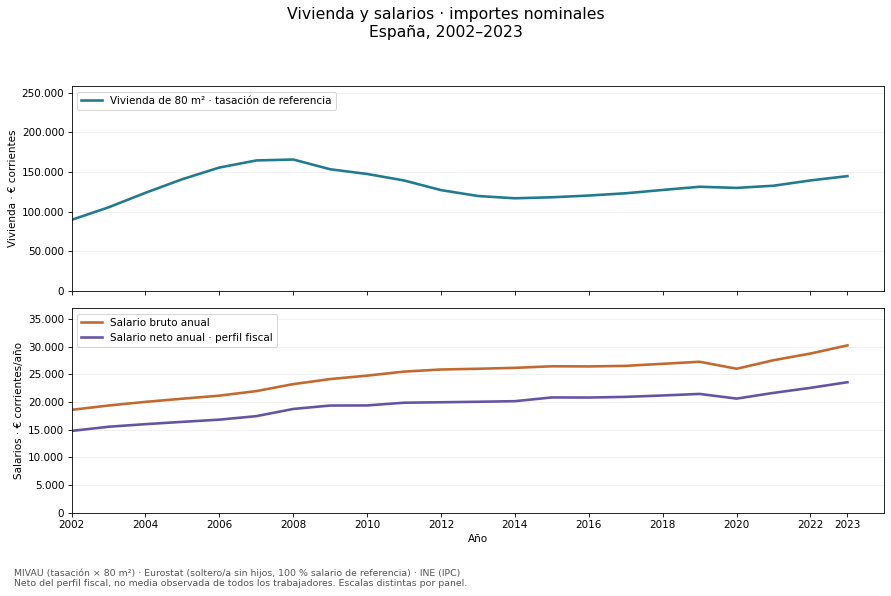

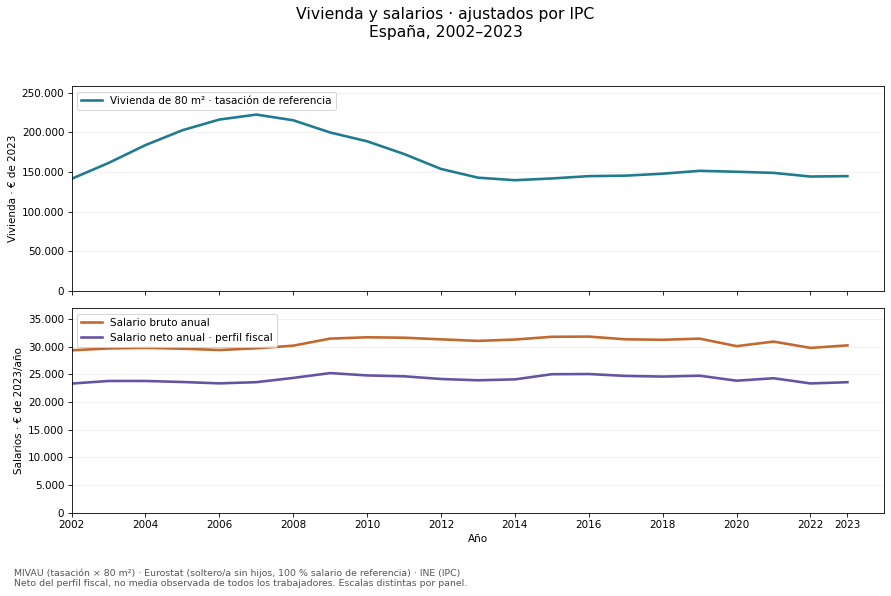

In [5]:
from matplotlib.ticker import FuncFormatter

money_format = FuncFormatter(lambda value, position: f"{value:,.0f}".replace(",", "."))
all_amounts = pd.concat([salary_nominal, salary_real])
housing_limit = all_amounts.iloc[:, 0].max() * 1.16
wage_limit = all_amounts.iloc[:, 1:].max().max() * 1.16
for salary_data, salary_name, salary_title, unit in [
    (salary_nominal, "16_housing_salary_nominal", "Vivienda y salarios · importes nominales", "€ corrientes"),
    (salary_real, "17_housing_salary_real", "Vivienda y salarios · ajustados por IPC", "€ de 2023"),
]:
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    axes[0].plot(salary_data.index, salary_data.iloc[:, 0], color="#207b8e", linewidth=2.5,
                 label="Vivienda de 80 m² · tasación de referencia")
    for column, color in zip(salary_data.columns[1:], ["#c2692f", "#6554a4"]):
        axes[1].plot(salary_data.index, salary_data[column], color=color, linewidth=2.5, label=column)
    axes[0].set(ylabel=f"Vivienda · {unit}", ylim=(0, housing_limit))
    axes[1].set(ylabel=f"Salarios · {unit}/año", ylim=(0, wage_limit), xlabel="Año")
    for ax in axes:
        ax.set_xlim(salary_base, salary_end + 1)
        ax.yaxis.set_major_formatter(money_format)
        ax.grid(axis="y", alpha=0.2)
        ax.legend(loc="upper left")
    axes[1].set_xticks(list(range(salary_base, salary_end + 1, 2)) + [salary_end])
    fig.suptitle(f"{salary_title}\nEspaña, {salary_base}–{salary_end}", fontsize=15)
    fig.text(0.02, 0.015,
             "MIVAU (tasación × 80 m²) · Eurostat (soltero/a sin hijos, 100 % salario de referencia) · INE (IPC)\n"
             "Neto del perfil fiscal, no media observada de todos los trabajadores. Escalas distintas por panel.",
             fontsize=9, color="#555555")
    fig.tight_layout(rect=(0, 0.065, 1, 0.94))
    fig.savefig(FIGURES / f"{salary_name}.png", dpi=120, bbox_inches="tight")
    display(fig)
    plt.close(fig)


### Cómo interpretar la comparación

Las líneas muestran cuánto valían la vivienda de referencia y los salarios en cada año. Bruto y neto se comparan en el mismo eje salarial. La figura en euros constantes permite observar sus cambios una vez descontado el IPC; **ninguna serie se fuerza a empezar en 100**.

El cociente vivienda/salario se expresa abajo como años de salario íntegro. No son años de ahorro ni una medida completa de accesibilidad: faltan gastos de vida, impuestos de compra, financiación, ahorro, ingresos del hogar y diferencias territoriales. Deflactar numerador y denominador con el mismo IPC no cambia ese cociente. Las curvas no identifican causas.


In [6]:
salary_changes = pd.DataFrame({
    "Importe inicial · € corrientes": salary_nominal.iloc[0],
    "Importe final · € corrientes": salary_nominal.iloc[-1],
    "Cambio nominal (%)": (salary_nominal.iloc[-1] / salary_nominal.iloc[0] - 1) * 100,
    "Cambio real, descontado IPC (%)": (salary_real.iloc[-1] / salary_real.iloc[0] - 1) * 100,
})
display(salary_changes.round(2))
for column in salary_nominal.columns[1:]:
    ratio = salary_nominal.iloc[:, 0] / salary_nominal[column]
    print(f"Vivienda de 80 m² / {column}: {ratio.iloc[0]:.2f} años de salario en {salary_base}; "
          f"{ratio.iloc[-1]:.2f} en {salary_end}.")


,Importe inicial · € corrientes,Importe final · € corrientes,Cambio nominal (%),"Cambio real, descontado IPC (%)"
Vivienda de 80 m²,89528.00,144726.00,61.65,2.41
Salario bruto anual,18600.78,30249.96,62.63,3.03
Salario neto anual · perfil fiscal,14793.85,23597.08,59.51,1.05


Vivienda de 80 m² / Salario bruto anual: 4.81 años de salario en 2002; 4.78 en 2023.
Vivienda de 80 m² / Salario neto anual · perfil fiscal: 6.05 años de salario en 2002; 6.13 en 2023.


## 3. Reproducir las figuras y tablas

El generador reproduce las 13 figuras originales. Las dos comparaciones salariales se reproducen en las celdas anteriores; las dos gráficas de diferencia de variación anual se reproduce en la sección 8. Los snapshots no se descargan.


In [7]:
figures, findings = run_analysis(ROOT)
print(f"{len(figures)} figuras de compra generadas.")
display(pd.read_csv(TABLES / "national_purchase_history.csv").round(2))

13 figuras de compra generadas.


,code,name,first_year,last_year,observed_years,missing_years,first_value,last_value,nominal_change_pct,real_first_year,real_last_year,real_change_pct,precrisis_peak_year,precrisis_peak_value,postcrisis_trough_year,postcrisis_trough_value,peak_to_trough_pct,trough_to_latest_pct,peak_to_latest_pct
0,0,España,2000,2025,26,0,880.22,2127.57,141.71,2002,2025,14.14,2008,2071.07,2014,1459.4,-29.53,45.78,2.73


## 4. Cambios anuales y ciclo

Extremos: máximo 2000–2008 y mínimo 2009–2015.

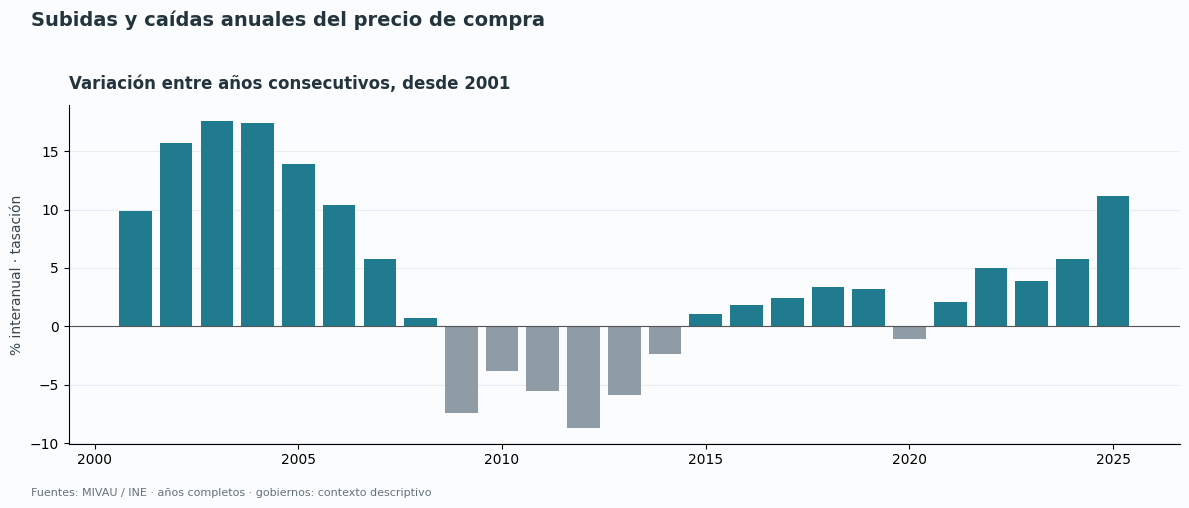

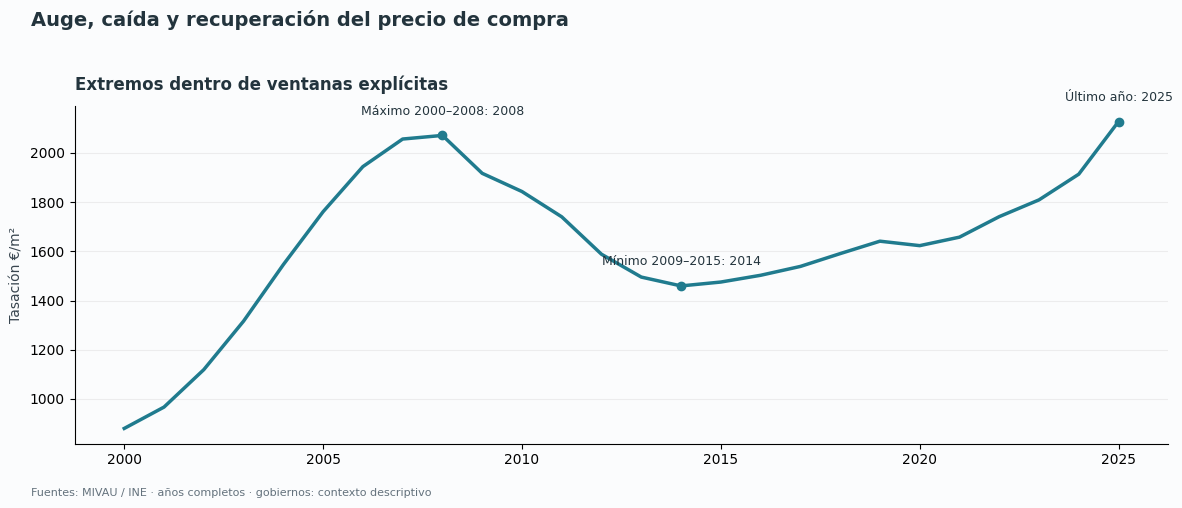

In [8]:
show("04_annual_changes", "05_purchase_cycle")

## 5. Comunidades y provincias

Nivel 2025 y cambio 2000–2025 con extremos fijos. Las tablas mantienen años ausentes y cobertura.

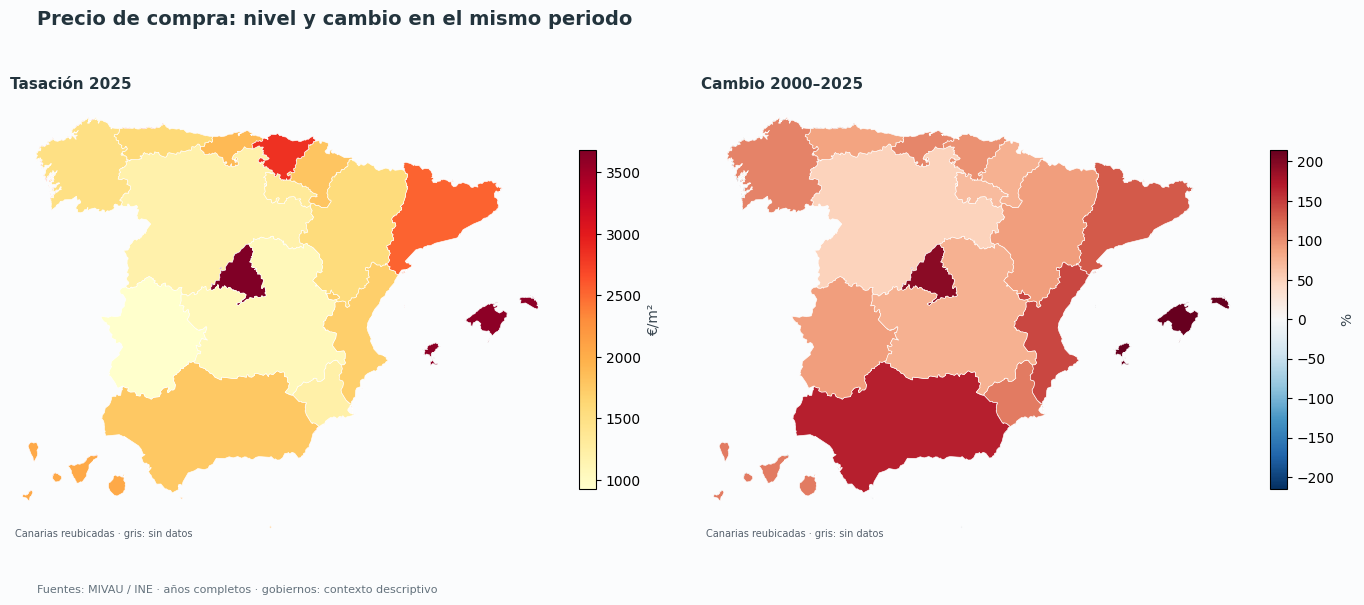

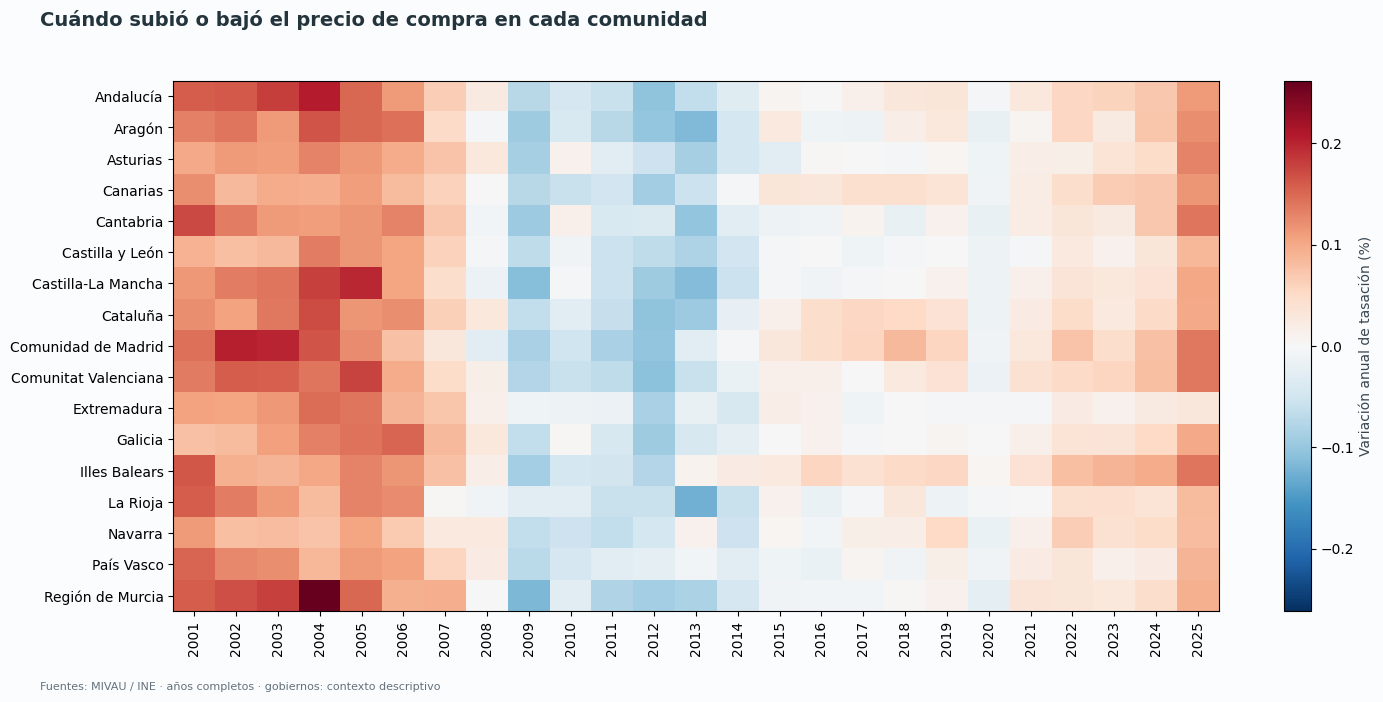

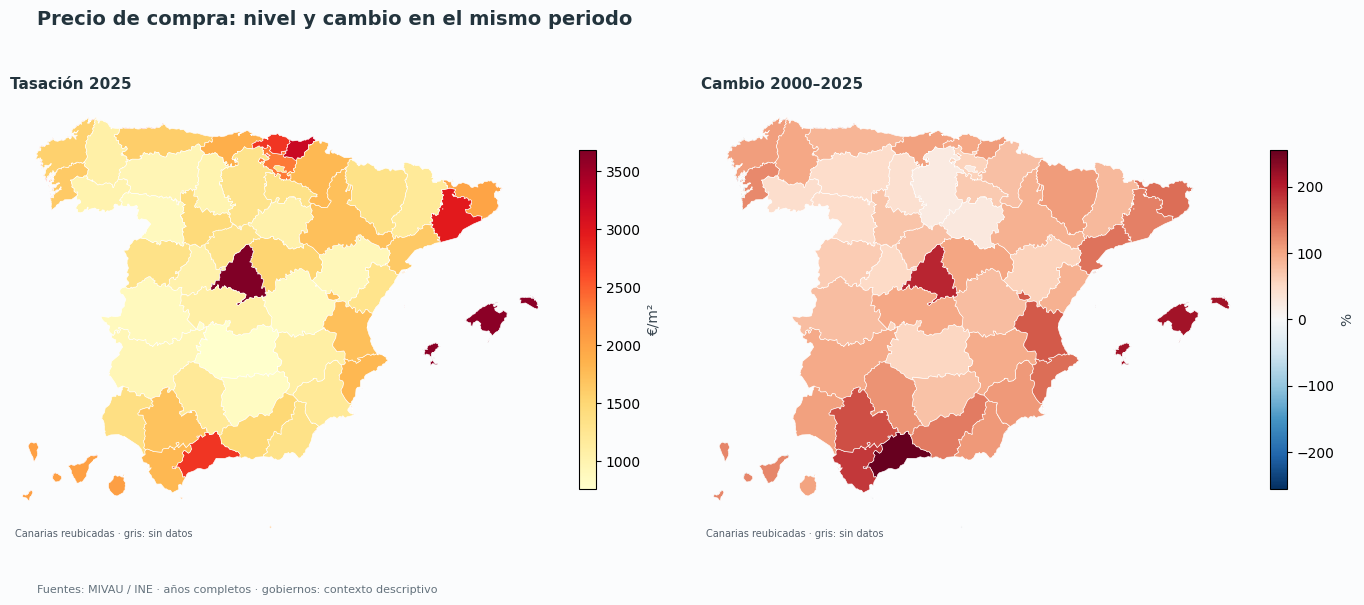

In [9]:
show("07_regional_maps", "08_regional_heatmap", "12_provincial_maps")

## 6. Municipios y perfiles

30 casos desde 2005; muestras fijas, medias no ponderadas. La selección no representa todos los municipios españoles.

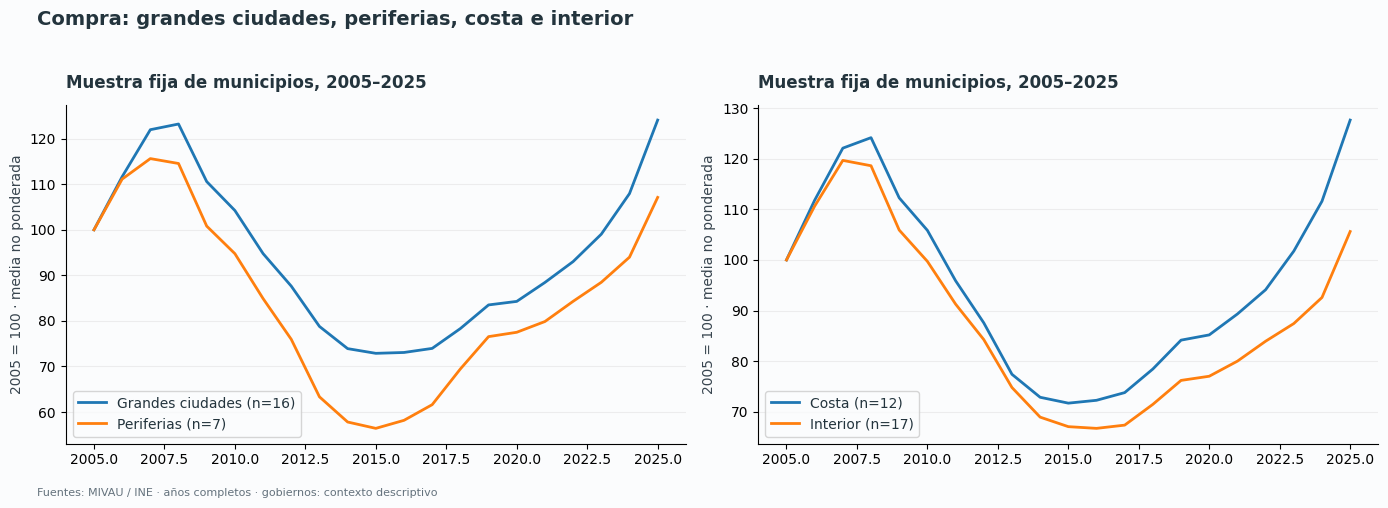

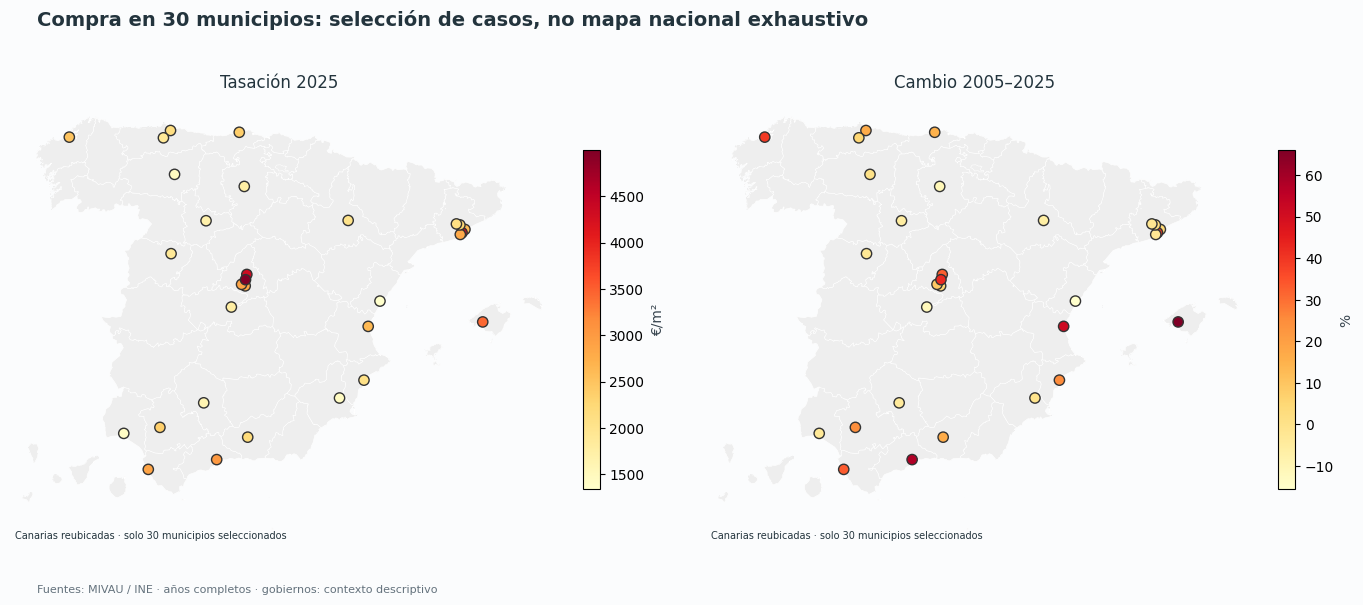

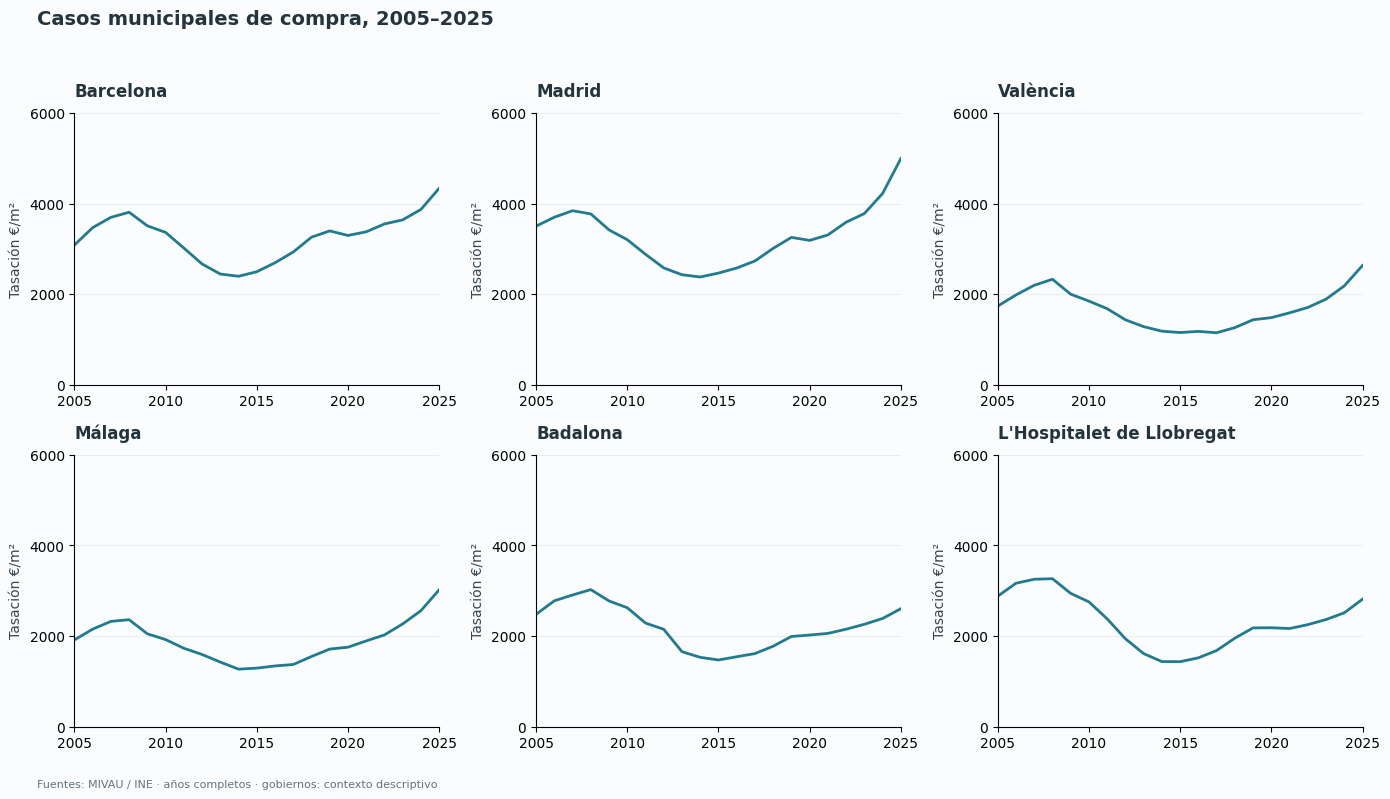

,code,name,year,value,growth_pct,urban_category,coastal_category
0,3014,Alacant/Alicante,2025,2069.35,25.38,large_city,coastal
1,7040,Palma,2025,3424.15,65.98,large_city,coastal
2,8015,Badalona,2025,2603.70,5.01,periphery,coastal
3,8019,Barcelona,2025,4339.92,40.59,large_city,coastal
4,8101,L'Hospitalet de Llobregat,2025,2812.72,-2.33,periphery,unclassified
5,8187,Sabadell,2025,2254.82,2.73,periphery,inland
6,8279,Terrassa,2025,2099.10,-1.78,periphery,inland
7,9059,Burgos,2025,1755.25,-10.57,selected_city,inland
8,11012,Cádiz,2025,2885.02,33.35,selected_city,coastal
9,12040,Castelló de la Plana/Castellón de la Plana,2025,1338.72,-15.58,selected_city,coastal


In [10]:
show("06_territorial_profiles", "13_municipal_maps", "15_municipal_cases")
display(pd.read_csv(TABLES / "selected_municipalities.csv").round(2))

## 7. Gobiernos como contexto temporal

Franjas de presidencias, sin atribución causal. Los periodos observados usan años completos dentro de cada mandato; no son un ranking de partidos.

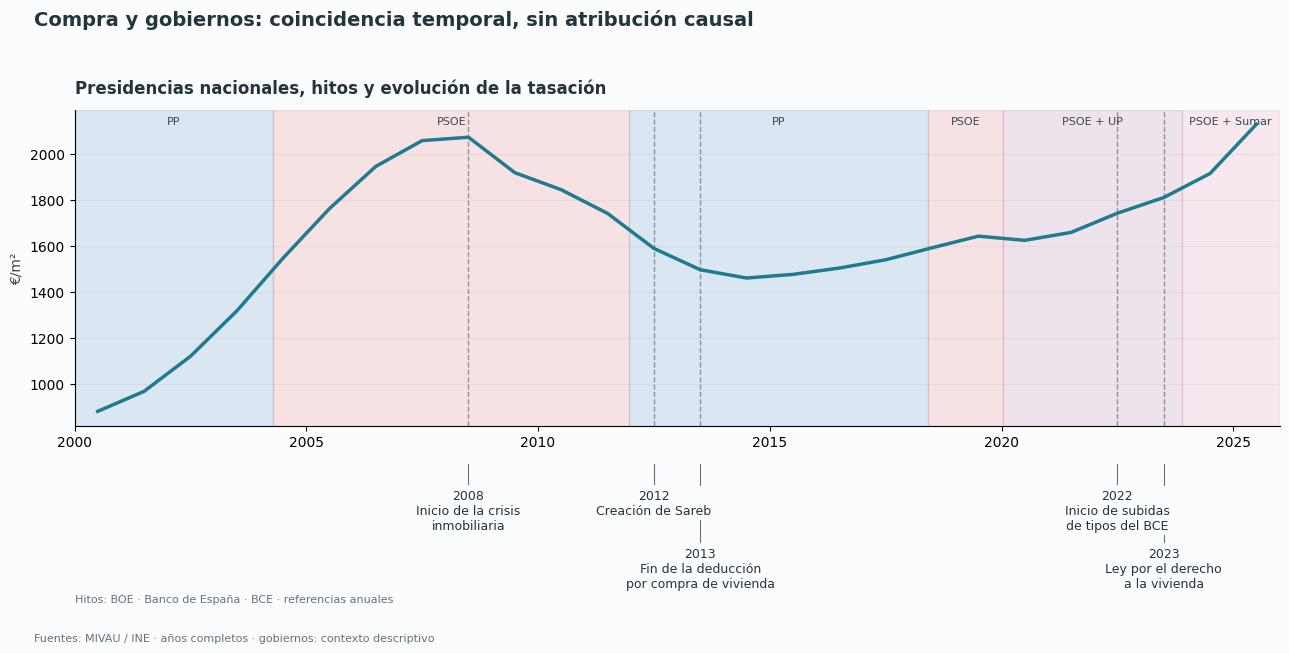

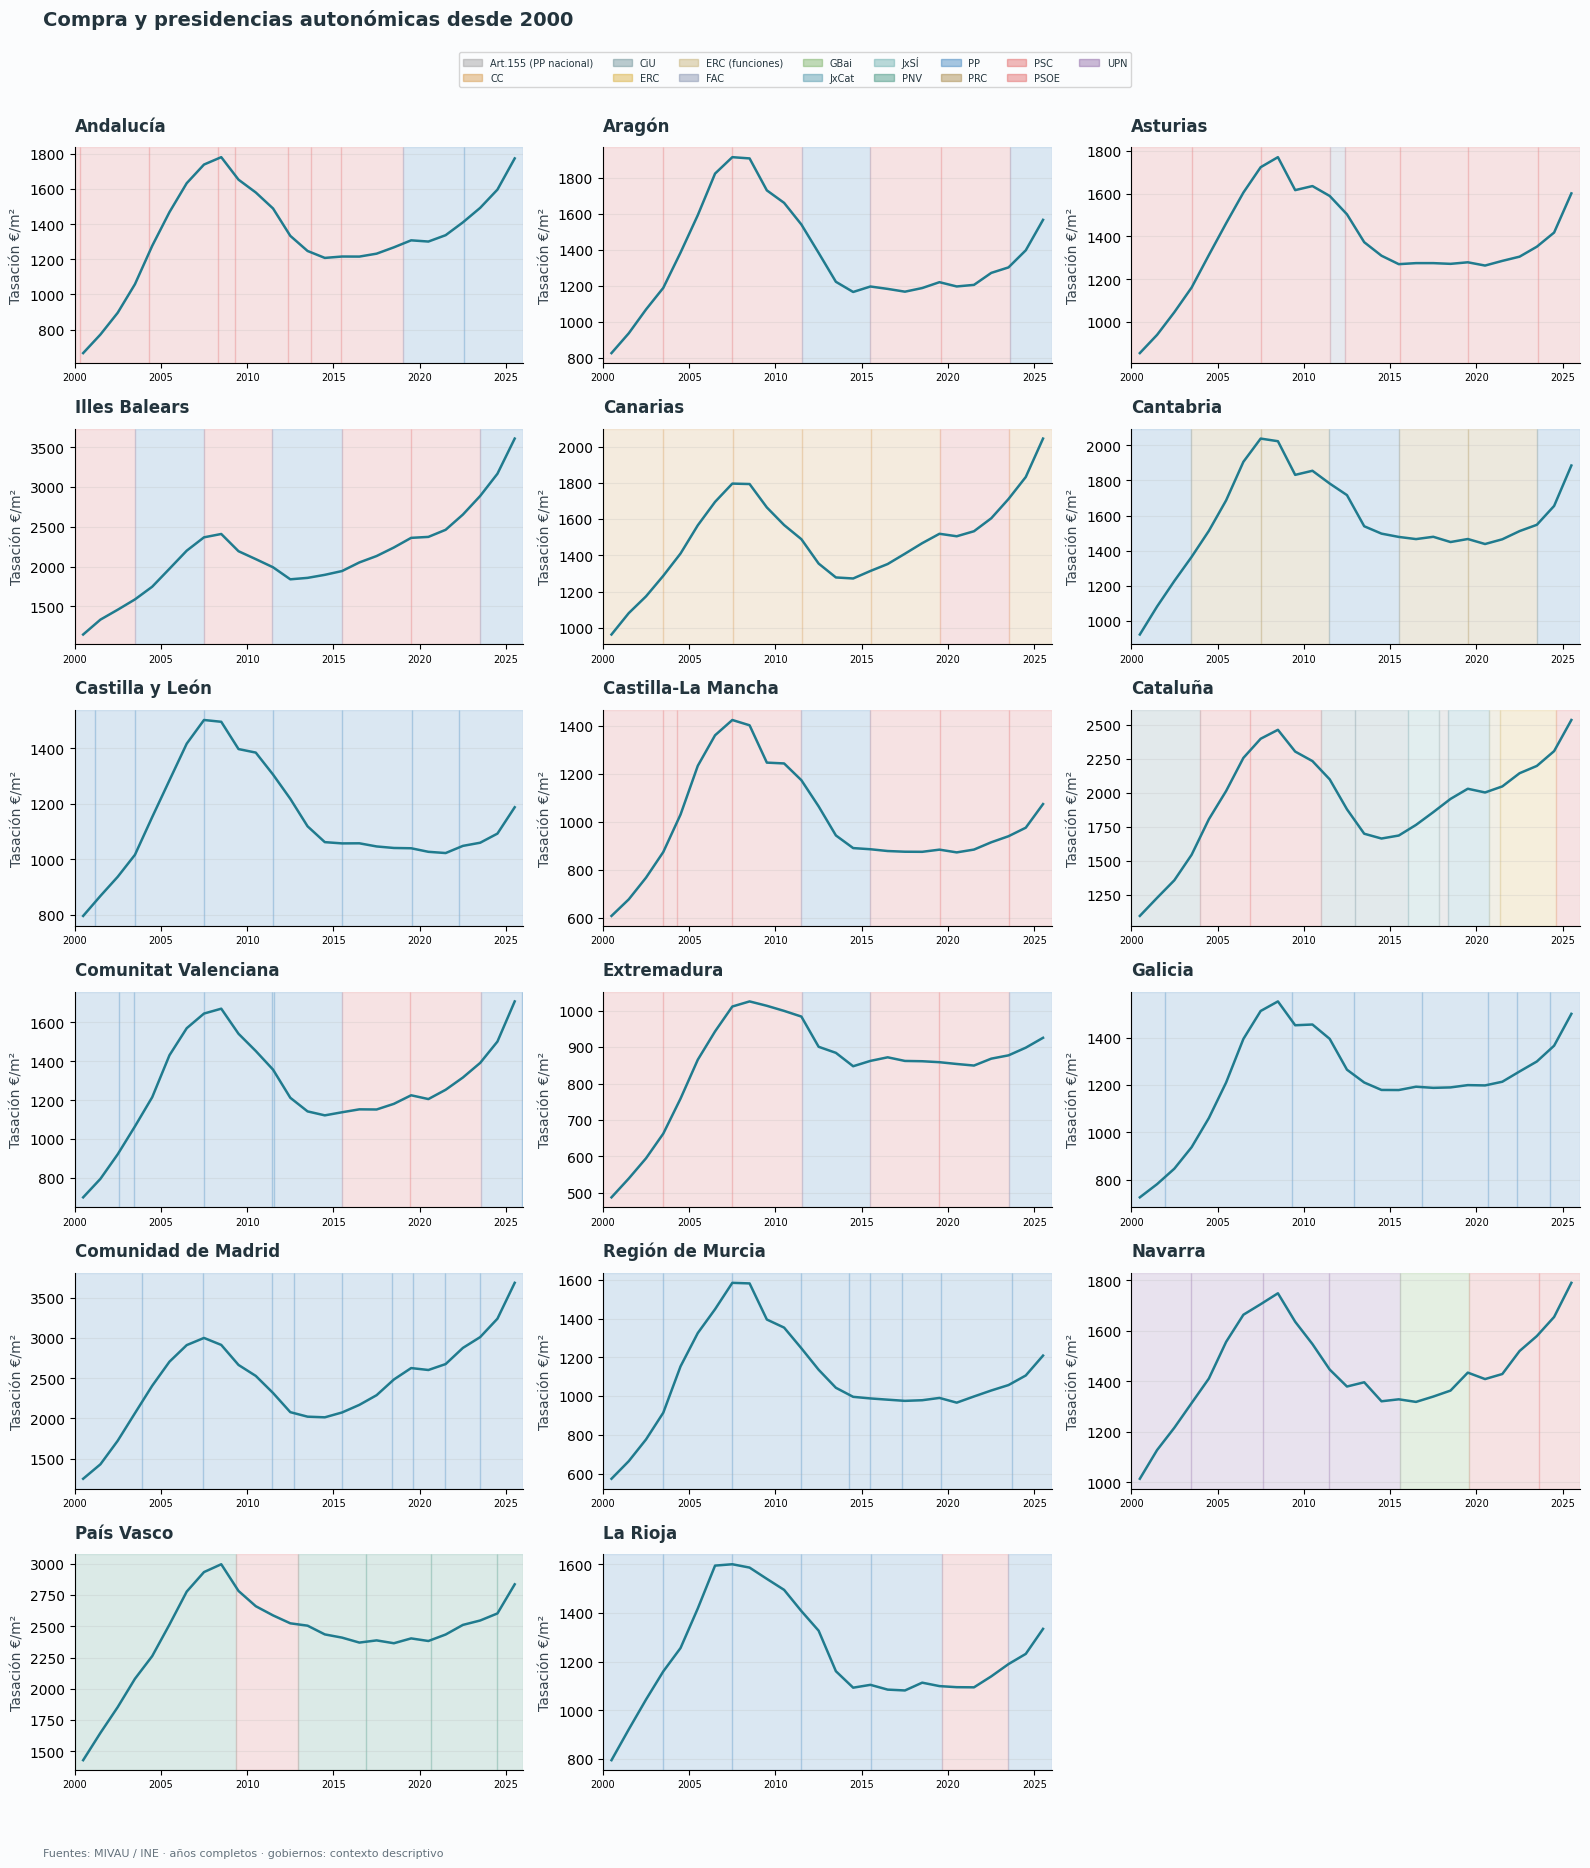

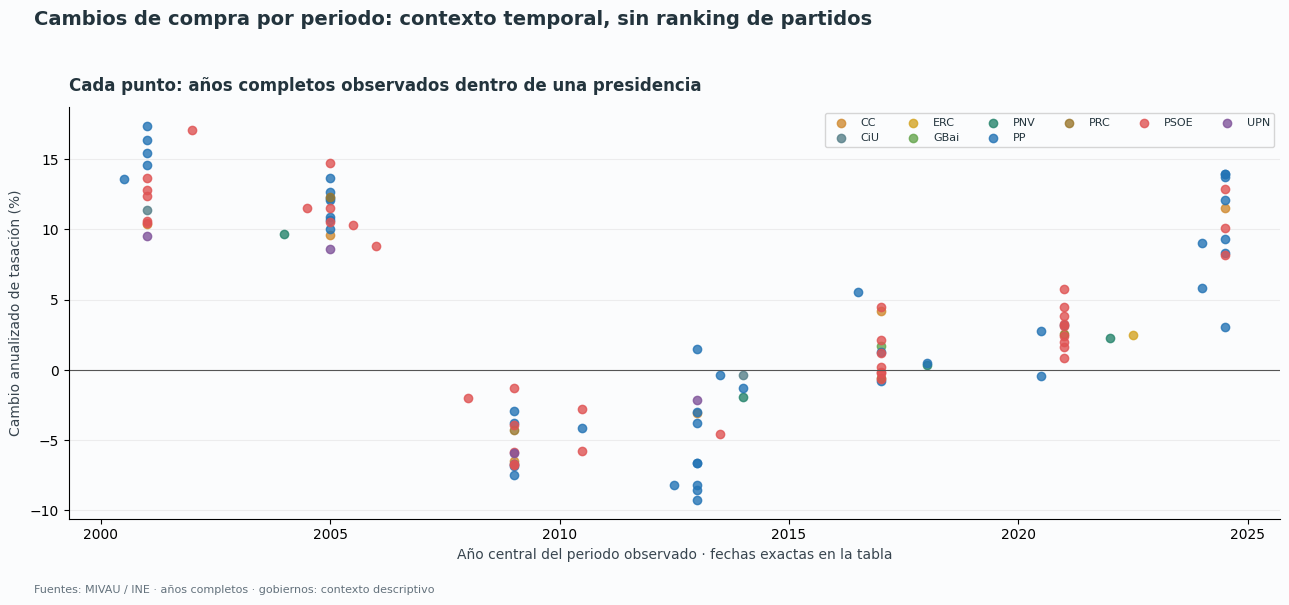

In [11]:
show("02_national_governments", "09_regional_governments_purchase", "10_mandate_comparison")

## 8. Diferencia de variación: vivienda frente a salario bruto y neto

Dos gráficas separadas, con **un único color y la misma escala**, muestran la diferencia anual entre la variación nominal de la vivienda y la del salario: una para el **bruto** y otra para el **neto del perfil fiscal**.

Cada tasa se calcula como `(valor actual / valor anterior - 1) × 100`. La barra representa **tasa de vivienda menos tasa salarial**, en **puntos porcentuales**. Por ejemplo, si la vivienda sube un 8 % y el salario un 3 %, la barra vale +5 puntos.

Una barra positiva significa que la vivienda sube más o cae menos que el salario; una negativa, que el salario sube más o cae menos que la vivienda. No es la variación porcentual del cociente vivienda/salario ni una medida completa de accesibilidad.

Se mantienen MIVAU, Eurostat y el perfil de la sección 2.1. Las barras cubren **2003–2023**, con observaciones de **2002–2023**. No se calculan cambios a través de años ausentes; 2024 sigue excluido por ruptura y valores anómalos. El neto pertenece al perfil fiscal, no a la media observada de todos los trabajadores. La superficie fija de 80 m² no modifica las tasas de vivienda.


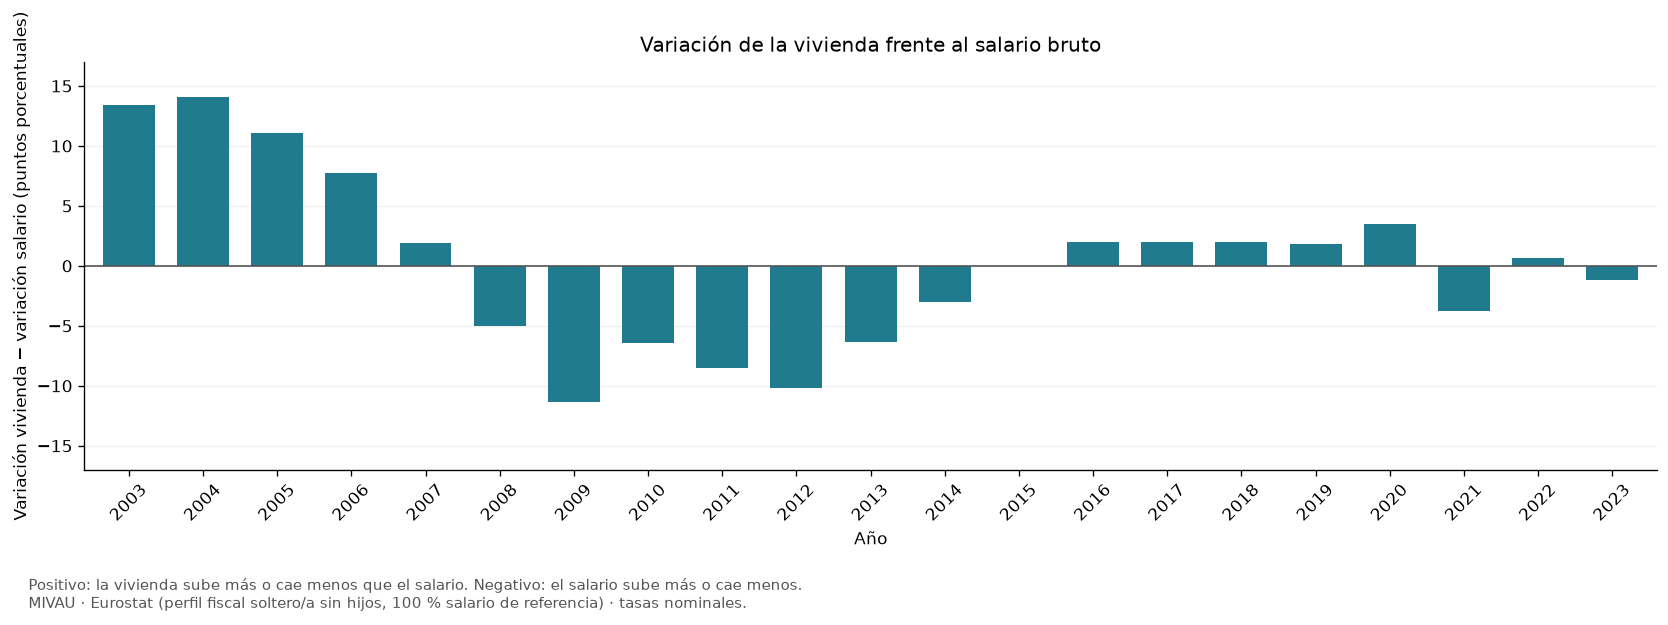

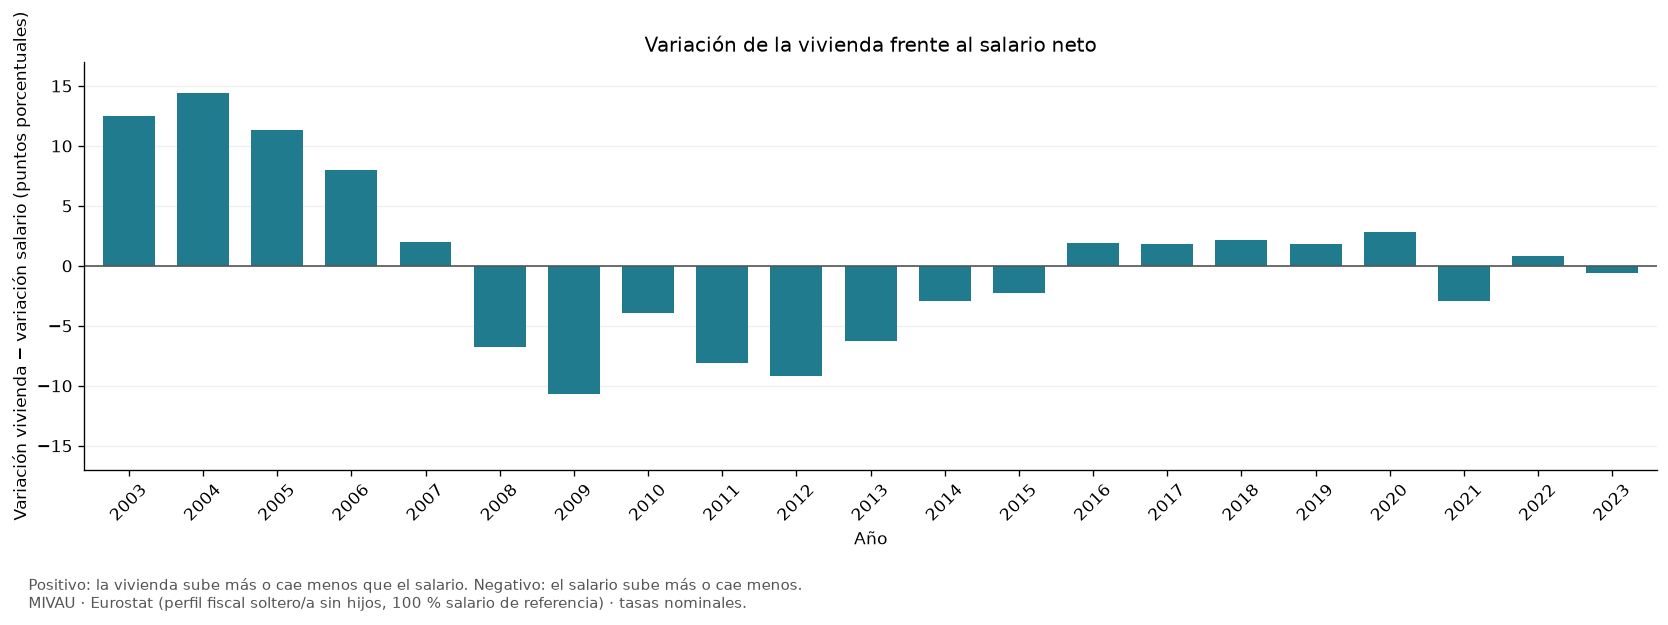

In [ ]:
from spain_housing.prices_analysis import annual_changes

# Diferencia entre tasas anuales: puntos porcentuales, no porcentaje del cociente.
salary_annual_changes = salary_nominal.apply(annual_changes).dropna(how="any")
salary_variation_gap = pd.DataFrame({
    "Vivienda frente a salario bruto": salary_annual_changes.iloc[:, 0] - salary_annual_changes.iloc[:, 1],
    "Vivienda frente a salario neto": salary_annual_changes.iloc[:, 0] - salary_annual_changes.iloc[:, 2],
})
salary_variation_gap.index.name = "year"
if salary_variation_gap.empty:
    raise ValueError("No hay años consecutivos comunes para comparar")
salary_variation_gap.to_csv(
    TABLES / "housing_salary_variation_gap.csv", float_format="%.8f"
)

# Misma escala y un único color en ambas figuras para facilitar la comparación.
gap_limit = max(1.0, salary_variation_gap.abs().max().max() * 1.18)
for column, name, salary_label in [
    (salary_variation_gap.columns[0], "18_housing_salary_gross_gap", "bruto"),
    (salary_variation_gap.columns[1], "19_housing_salary_net_gap", "neto"),
]:
    fig, ax = plt.subplots(figsize=(14, 5))
    salary_variation_gap[column].plot.bar(ax=ax, color="#207b8e", width=0.7, rot=45)
    ax.axhline(0, color="#555555", linewidth=1)
    ax.set(
        title=f"Variación de la vivienda frente al salario {salary_label}",
        xlabel="Año",
        ylabel="Variación vivienda − variación salario (puntos porcentuales)",
        ylim=(-gap_limit, gap_limit),
    )
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    fig.text(
        0.02, 0.015,
        "Positivo: la vivienda sube más o cae menos que el salario. Negativo: el salario sube más o cae menos.\n"
        "MIVAU · Eurostat (perfil fiscal soltero/a sin hijos, 100 % salario de referencia) · tasas nominales.",
        fontsize=9, color="#555555",
    )
    fig.tight_layout(rect=(0, 0.085, 1, 1))
    fig.savefig(FIGURES / f"{name}.png", dpi=120, bbox_inches="tight")
    display(fig)
    plt.close(fig)
display(salary_variation_gap.round(2))
